# 04 – Deep learning single-model daily MSW forecasting

Four deep learning architectures, each trained **independently** on each preprocessed dataset (no ensembles):
**LSTM**, **TCN**, **Transformer** and **N-BEATS**.

Built with **Keras 3 on the JAX backend**. JAX uses a Colab **TPU** automatically when the runtime is a TPU, otherwise a GPU, otherwise the CPU.
The same code runs everywhere.

## Experimental design (same protocol as `02_ml_single_model.ipynb`)

| Item | Setting |
|---|---|
| Series | each dataset is one continuous daily series in chronological order |
| Split | first **70 %** of days = training, last **30 %** = test (same split date as 02 and 03) |
| Validation | the **last 15 % of the training windows** (chronological), used for early stopping and for choosing between the candidate settings. The test period is never used for selection. |
| Forecast | **one-step-ahead** (horizon = 1 day), rolling origin. The forecast for day *t* uses only the previous `LOOKBACK` days (up to *t−1*). The model is trained once and not updated during the test period. |
| Scaling | standardisation (mean and std) fitted on the **training period only**, then applied to validation and test. Predictions are inverse-transformed before evaluation. |
| Scored days | real recorded days only (imputed days and filled closure zeros excluded), as in 02 |
| Metrics | MAE, RMSE, MAPE. Days with actual = 0 are excluded from MAPE only (`n_zero_excluded_from_MAPE`). Primary metric: RMSE. |
| Post-processing | predictions clipped at 0 |

Training targets are real days only. Inputs (the past window) may contain imputed values, the same as in 02.

## From a series to training examples (windows)

With `LOOKBACK = 28` and `HORIZON = 1`, every training example is:

```
input  X: the 28 days before day t   →  y[t-28], y[t-27], ..., y[t-1]
target Y: day t                      →  y[t]
```

The window slides one day at a time. A window is a **training** example if its target day is in the training period, and a **test** example if its target day is in the test period.
Test inputs can reach back into the end of the training period and include earlier test days. Those values were already observed when the forecast is made, so there is no leakage.

**Tensor shapes**

| Tensor | Shape | Meaning |
|---|---|---|
| `X` | `(n_windows, LOOKBACK, 1)` | batch of windows, `LOOKBACK` time steps, 1 feature (scaled waste) |
| `Y` | `(n_windows, 1)` | the next day's scaled waste |
| N-BEATS input | `(n_windows, LOOKBACK)` | the window flattened into a vector (done inside the model) |
| model output | `(n_windows, 1)` | the forecast for day *t*, inverse-scaled to kg afterwards |

## Speed

Earlier experiments took a long time, so this notebook is built to be fast:
- small models (tens of thousands of parameters), short windows (28 days), batch size 64
- early stopping (stops when the validation loss has not improved for `PATIENCE` epochs) with an epoch limit
- only **2 candidate settings per architecture** (`QUICK_RUN = True` uses only the first one)
- the best model from the selection run is kept (no extra retraining), and the whole test period is predicted in one batched call

Expected time: a few minutes per dataset on a GPU or CPU. **TPU note:** for models this small, a TPU is not always faster,
because every new model is first compiled. If the TPU feels slow, switch the runtime to a T4 GPU. The notebook runs unchanged.

## 1. Setup and device

In [1]:
import os, sys, gc, time, random, traceback, warnings

KERAS_BACKEND = "jax"                     # "jax" (TPU/GPU/CPU), or "tensorflow" / "torch"
os.environ["KERAS_BACKEND"] = KERAS_BACKEND

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import keras
from keras import layers

warnings.filterwarnings("ignore")
print("Keras", keras.__version__, "| backend:", keras.backend.backend())

if KERAS_BACKEND == "jax":
    import jax
    print("Devices:", jax.devices())      # shows TPU / GPU / CPU devices automatically
elif KERAS_BACKEND == "tensorflow":
    import tensorflow as tf
    print("Devices:", tf.config.list_logical_devices())

SEED = 42
def set_seeds(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    keras.utils.set_random_seed(seed)     # Python, NumPy and backend seeds
set_seeds()

Keras 3.13.2 | backend: jax
Devices: [CudaDevice(id=0)]


In [2]:
import os

# ---------------- Paths (files uploaded to the current Colab folder) ----------------
OUTPUT_DIR = "results_dl"
os.makedirs(OUTPUT_DIR, exist_ok=True)

DATASETS = {
    "Moratuwa":      "daily_waste_output_Moratuwa_datefixed.csv",
    "Dehiwala":      "daily_waste_output_dehiwala_datefixed.csv",
    "Boralasgamuwa": "daily_waste_output_boralasgamuwa_datefixed.csv",
    "Ballarat":      "daily_waste_output_ballarat_datefixed.csv",
    "Austin":        "daily_waste_output_austin_datefixed.csv",    # remove this line to use only the four councils
}

# Check that every file is in the folder before going further
for name, file_name in DATASETS.items():
    print(f"{name:14} {'found' if os.path.exists(file_name) else 'MISSING'}  {file_name}")

Moratuwa       found  daily_waste_output_Moratuwa_datefixed.csv
Dehiwala       found  daily_waste_output_dehiwala_datefixed.csv
Boralasgamuwa  found  daily_waste_output_boralasgamuwa_datefixed.csv
Ballarat       found  daily_waste_output_ballarat_datefixed.csv
Austin         found  daily_waste_output_austin_datefixed.csv


In [3]:
# ---------------- All settings in one place ----------------
CONFIG = {
    "test_ratio": 0.30,
    "lookback": 28,                 # days of history per input window
    "lookback_fallbacks": [14, 7],  # used if a dataset is too short for "lookback"
    "horizon": 1,                   # one-step-ahead, same as the ML notebooks
    "val_fraction": 0.15,           # last 15 % of the training windows = validation
    "min_train_windows": 100,       # smallest number of real training windows
    "batch_size": 64,
    "max_epochs": 60,
    "patience": 8,                  # early stopping patience (epochs)
    "loss": "mse",                  # matches RMSE, the primary metric ("huber" is more robust to spikes)
    "clipnorm": 1.0,
    "primary_metric": "RMSE",
}
QUICK_RUN = False                   # True = only the first candidate setting per architecture (fastest)

MODEL_GRIDS = {
    "LSTM":        [{"units": 32, "dropout": 0.1, "lr": 1e-3},
                    {"units": 64, "dropout": 0.1, "lr": 1e-3}],
    "TCN":         [{"filters": 32, "kernel_size": 3, "dilations": [1, 2, 4, 8], "dropout": 0.1, "lr": 1e-3},
                    {"filters": 64, "kernel_size": 3, "dilations": [1, 2, 4, 8], "dropout": 0.1, "lr": 1e-3}],
    "Transformer": [{"d_model": 32, "heads": 2, "layers": 1, "ff_dim": 64, "dropout": 0.1, "lr": 1e-3},
                    {"d_model": 32, "heads": 4, "layers": 2, "ff_dim": 64, "dropout": 0.1, "lr": 5e-4}],
    "N-BEATS":     [{"units": 128, "blocks": 3, "layers_per_block": 3, "lr": 1e-3},
                    {"units": 256, "blocks": 3, "layers_per_block": 4, "lr": 1e-3}],
}
assert CONFIG["horizon"] == 1, "evaluation protocol is one-step-ahead, as in 02 and 03"

## 2. Data loading (identical to 02)

In [4]:
def load_dataset(name, file_name):
    """Continuous daily series with y (kg) and scored (True = real recorded day)."""
    path = file_name                                   # file is in the current Colab folder
    if not os.path.exists(path):
        raise FileNotFoundError(f"{path} not found – upload the CSV to Colab first")
    df = pd.read_csv(path)
    df["ticket_date"] = pd.to_datetime(df["ticket_date"], utc=True).dt.tz_localize(None).dt.normalize()
    df = df.sort_values("ticket_date").set_index("ticket_date")
    if df.index.duplicated().any():
        raise ValueError(f"{name}: duplicate dates")
    full = pd.date_range(df.index.min(), df.index.max(), freq="D")
    if len(full) != len(df):
        raise ValueError(f"{name}: series is not continuous ({len(full) - len(df)} days missing)")
    if df["net_weight_kg"].isna().any():
        raise ValueError(f"{name}: net_weight_kg still has blanks")
    out = pd.DataFrame(index=full)
    out["y"] = df["net_weight_kg"].astype(float)
    not_real = pd.Series(False, index=full)
    for flag in ["is_imputed", "is_closure_zero"]:
        if flag in df.columns:
            not_real |= df[flag].astype(bool)
    out["scored"] = ~not_real
    return out


def time_split_index(n_days, test_ratio=CONFIG["test_ratio"]):
    return int(round(n_days * (1 - test_ratio)))


data = {}
for name, file_name in DATASETS.items():
    try:
        data[name] = load_dataset(name, file_name)
        print(f"[OK] {name}: {len(data[name])} days")
    except Exception as e:
        print(f"[FAILED] dataset={name} step=data loading: {type(e).__name__}: {e}")
if not data:
    raise RuntimeError("No dataset could be loaded – upload the CSV files to Colab first")

pd.DataFrame([{"dataset": n, "days": len(d), "train_days": time_split_index(len(d)),
               "test_start": d.index[time_split_index(len(d))].date()} for n, d in data.items()]).set_index("dataset")

[OK] Moratuwa: 1461 days
[OK] Dehiwala: 1461 days
[OK] Boralasgamuwa: 2557 days
[OK] Ballarat: 4017 days
[OK] Austin: 2556 days


,days,train_days,test_start
dataset,,,
Moratuwa,1461,1023,2017-10-20
Dehiwala,1461,1023,2014-10-20
Boralasgamuwa,2557,1790,2016-11-25
Ballarat,4017,2812,2008-09-13
Austin,2556,1789,2009-11-25


## 3. Scaling and windows

The scaler is fitted on the training period only. Windows are made from the scaled series.
A window's **target position** decides whether it belongs to training, validation or test.

In [5]:
class TrainOnlyScaler:
    """Standardisation with mean/std from the training period only."""
    def fit(self, values):
        self.mean = float(np.mean(values))
        self.std = float(np.std(values)) or 1.0
        return self
    def transform(self, values):
        return (np.asarray(values, dtype="float32") - self.mean) / self.std
    def inverse(self, values):
        return np.asarray(values, dtype="float64") * self.std + self.mean


def make_windows(values, lookback):
    """X[i] = values[i : i+lookback] (past), Y[i] = values[i+lookback] (next day).
    Returns X (n, lookback, 1), Y (n, 1) and the target position of every window."""
    X = np.lib.stride_tricks.sliding_window_view(values[:-1], lookback)
    Y = values[lookback:]
    target_pos = np.arange(lookback, len(values))
    return X[..., None].astype("float32"), Y[:, None].astype("float32"), target_pos


class InsufficientData(Exception):
    pass


def prepare_dataset(d):
    """Scale, window and split one dataset. Falls back to shorter lookbacks if the data is too short."""
    n_train = time_split_index(len(d))
    scaler = TrainOnlyScaler().fit(d["y"].iloc[:n_train].to_numpy())
    scaled = scaler.transform(d["y"].to_numpy())
    scored = d["scored"].to_numpy()

    for lookback in [CONFIG["lookback"]] + CONFIG["lookback_fallbacks"]:
        if n_train <= lookback:
            continue
        X, Y, pos = make_windows(scaled, lookback)
        train_mask = (pos < n_train) & scored[pos]                  # real training targets only
        if train_mask.sum() < CONFIG["min_train_windows"]:
            continue
        train_idx = np.flatnonzero(train_mask)
        n_val = max(int(len(train_idx) * CONFIG["val_fraction"]), 1)
        fit_idx, val_idx = train_idx[:-n_val], train_idx[-n_val:]   # chronological: validation = latest windows
        test_idx = np.flatnonzero(pos >= n_train)                   # every test day gets a forecast
        return {"lookback": lookback, "scaler": scaler, "X": X, "Y": Y, "pos": pos,
                "fit_idx": fit_idx, "val_idx": val_idx, "test_idx": test_idx, "n_train": n_train}
    raise InsufficientData(f"fewer than {CONFIG['min_train_windows']} real training windows even with "
                           f"lookback {CONFIG['lookback_fallbacks'][-1]}")

## 4. The four architectures (beginner-friendly)

All four read the same input (the last `LOOKBACK` days) and output one number (the next day's waste).

### LSTM – Long Short-Term Memory
An LSTM reads the window **one day at a time, from oldest to newest**, and keeps a "memory" (cell state) that it updates at each step.
*Gates* decide what to keep, forget and output, so it can remember, for example, that waste was high last week.
The memory after the last day (*t−1*) goes into a dense layer that outputs the forecast.
It reads strictly forward in time, so it is causal by construction.

### TCN – Temporal Convolutional Network
A TCN slides small filters along the window, like a pattern detector.
- **Causal convolutions**: the output at step *k* only looks at steps ≤ *k* (padding is added on the left only), so the future cannot leak in.
- **Dilations** (1, 2, 4, 8): each layer skips more steps, so a few layers cover the whole window. With kernel 3 and dilations 1–8, each output sees 61 days, more than the 28-day window.
- **Residual connections** add each block's input to its output, which makes training stable.

The features at the last step (day *t−1*, which has seen the whole window) produce the forecast.

### Transformer
A Transformer compares every day in the window with every other day (**self-attention**) and learns which past days matter most for the forecast.
- Each day's value is projected to a vector of size `d_model`, and a learned **positional embedding** says where in the window each day is.
- **Causal mask**: day *k* can only attend to days ≤ *k*. The window itself contains only past days, and the mask also keeps attention causal inside it.
- Each layer = multi-head attention + a small feed-forward network, both with residual connections and layer normalisation.

The output at the last position (day *t−1*) produces the forecast.

### N-BEATS – Neural Basis Expansion Analysis
N-BEATS uses only fully connected layers. The window is flattened into one vector and passed through a chain of **blocks**.
Each block outputs:
- a **backcast**: its own reconstruction of the input window, which is subtracted, so the next block only sees what is still unexplained
- a **forecast**: its contribution to the next day

The final forecast is the **sum of all block forecasts**. It is simple, fast, and often strong on univariate series.

In [6]:
class PositionalEmbedding(layers.Layer):
    """Learned position vector added to each time step (the Transformer has no built-in sense of order)."""
    def __init__(self, length, dim, **kwargs):
        super().__init__(**kwargs)
        self.length, self.dim = length, dim

    def build(self, input_shape):
        self.pos = self.add_weight(shape=(self.length, self.dim), initializer="random_normal", name="pos")

    def call(self, x):
        return x + self.pos


def build_lstm(lookback, p):
    inp = keras.Input(shape=(lookback, 1))                       # (batch, lookback, 1)
    x = layers.LSTM(p["units"])(inp)                             # (batch, units): memory after day t-1
    x = layers.Dropout(p["dropout"])(x)
    out = layers.Dense(1)(x)                                     # (batch, 1)
    return keras.Model(inp, out, name="LSTM")


def build_tcn(lookback, p):
    inp = keras.Input(shape=(lookback, 1))
    x = inp
    for d in p["dilations"]:
        h = layers.Conv1D(p["filters"], p["kernel_size"], padding="causal", dilation_rate=d, activation="relu")(x)
        h = layers.Dropout(p["dropout"])(h)
        h = layers.Conv1D(p["filters"], p["kernel_size"], padding="causal", dilation_rate=d, activation="relu")(h)
        if x.shape[-1] != p["filters"]:
            x = layers.Conv1D(p["filters"], 1)(x)                # match channels for the residual
        x = layers.Add()([x, h])                                 # (batch, lookback, filters)
    x = x[:, -1, :]                                              # last step = day t-1
    out = layers.Dense(1)(x)
    return keras.Model(inp, out, name="TCN")


def build_transformer(lookback, p):
    inp = keras.Input(shape=(lookback, 1))
    x = layers.Dense(p["d_model"])(inp)                          # (batch, lookback, d_model)
    x = PositionalEmbedding(lookback, p["d_model"])(x)
    for _ in range(p["layers"]):
        attn = layers.MultiHeadAttention(num_heads=p["heads"], key_dim=p["d_model"] // p["heads"],
                                         dropout=p["dropout"])(x, x, use_causal_mask=True)
        x = layers.LayerNormalization()(layers.Add()([x, attn]))
        ff = layers.Dense(p["ff_dim"], activation="relu")(x)
        ff = layers.Dense(p["d_model"])(ff)
        x = layers.LayerNormalization()(layers.Add()([x, ff]))
    x = x[:, -1, :]                                              # last position = day t-1
    out = layers.Dense(1)(x)
    return keras.Model(inp, out, name="Transformer")


def build_nbeats(lookback, p):
    inp = keras.Input(shape=(lookback, 1))
    residual = layers.Flatten()(inp)                             # (batch, lookback)
    forecast = None
    for _ in range(p["blocks"]):
        h = residual
        for _ in range(p["layers_per_block"]):
            h = layers.Dense(p["units"], activation="relu")(h)
        backcast = layers.Dense(lookback)(h)                     # reconstruction of the input
        block_forecast = layers.Dense(1)(h)                      # this block's share of the forecast
        residual = layers.Subtract()([residual, backcast])
        forecast = block_forecast if forecast is None else layers.Add()([forecast, block_forecast])
    return keras.Model(inp, forecast, name="N_BEATS")


BUILDERS = {"LSTM": build_lstm, "TCN": build_tcn, "Transformer": build_transformer, "N-BEATS": build_nbeats}

## 5. Training, selection and one-step-ahead prediction

For each candidate setting:
1. build the model and train it on the training windows with **Adam**, the configured loss and gradient clipping
2. use **early stopping** on the validation windows (best weights are restored)
3. compute the validation RMSE in kg

The candidate with the lowest validation RMSE is kept and predicts all test windows in one call.

In [7]:
def metrics_kg(actual, predicted):
    """MAE, RMSE, MAPE in kg. Zero actual values are excluded from MAPE only (reported separately)."""
    a = np.asarray(actual, dtype=float)
    p = np.asarray(predicted, dtype=float)
    err = a - p
    nonzero = a != 0
    return {"MAE": float(np.mean(np.abs(err))), "RMSE": float(np.sqrt(np.mean(err ** 2))),
            "MAPE_%": float(np.mean(np.abs(err[nonzero] / a[nonzero])) * 100) if nonzero.any() else np.nan,
            "n_scored": int(len(a)), "n_zero_excluded_from_MAPE": int((~nonzero).sum())}


def train_one(model_name, params, prep):
    """Train one candidate. Returns the model, its history and the validation RMSE in kg."""
    keras.backend.clear_session()
    set_seeds()
    model = BUILDERS[model_name](prep["lookback"], params)
    model.compile(optimizer=keras.optimizers.Adam(learning_rate=params["lr"], clipnorm=CONFIG["clipnorm"]),
                  loss=CONFIG["loss"])
    X, Y = prep["X"], prep["Y"]
    fit, val = prep["fit_idx"], prep["val_idx"]
    history = model.fit(
        X[fit], Y[fit], validation_data=(X[val], Y[val]),
        epochs=CONFIG["max_epochs"], batch_size=CONFIG["batch_size"],
        shuffle=True,                       # shuffles batch order inside the training windows only
        callbacks=[keras.callbacks.EarlyStopping(monitor="val_loss", patience=CONFIG["patience"],
                                                 restore_best_weights=True)],
        verbose=0)
    val_pred = prep["scaler"].inverse(model.predict(X[val], batch_size=512, verbose=0)[:, 0])
    val_true = prep["scaler"].inverse(Y[val][:, 0])
    val_rmse = float(np.sqrt(np.mean((val_true - val_pred) ** 2)))
    return model, pd.DataFrame(history.history), val_rmse


def run_dl_model(model_name, d):
    prep = prepare_dataset(d)
    grid = MODEL_GRIDS[model_name][:1] if QUICK_RUN else MODEL_GRIDS[model_name]
    best = None
    selection = []
    for i, params in enumerate(grid):
        model, hist, val_rmse = train_one(model_name, params, prep)
        selection.append({"candidate": i, **{k: str(v) for k, v in params.items()},
                          "val_rmse_kg": val_rmse, "epochs_run": len(hist),
                          "best_epoch": int(hist["val_loss"].idxmin()) + 1, "params_count": model.count_params()})
        if best is None or val_rmse < best["val_rmse"]:
            best = {"model": model, "history": hist, "val_rmse": val_rmse, "params": params}
        else:
            del model

    test_idx = prep["test_idx"]
    pred_scaled = best["model"].predict(prep["X"][test_idx], batch_size=512, verbose=0)[:, 0]
    pred = np.clip(prep["scaler"].inverse(pred_scaled), 0, None)
    dates = d.index[prep["pos"][test_idx]]
    result = pd.DataFrame({"actual": d["y"].reindex(dates).to_numpy(), "predicted": pred,
                           "scored": d["scored"].reindex(dates).to_numpy()}, index=dates)
    result.index.name = "date"
    expected = d.index[prep["n_train"]:]
    if not result.index.equals(expected):
        raise ValueError("test predictions do not cover the test period exactly")
    return result, best, pd.DataFrame(selection), prep["lookback"]

## 6. Run every dataset × architecture

In [8]:
def safe_name(text):
    return "".join(c if c.isalnum() else "_" for c in text).strip("_")


def plot_loss(history, title, path):
    fig, ax = plt.subplots(figsize=(8, 4))
    ax.plot(history["loss"], label="training loss")
    ax.plot(history["val_loss"], label="validation loss")
    ax.axvline(int(history["val_loss"].idxmin()), color="grey", ls="--", lw=1, label="best epoch")
    ax.set_xlabel("epoch"); ax.set_ylabel(f"{CONFIG['loss']} (scaled)"); ax.set_title(title)
    ax.legend(); ax.grid(alpha=0.3); fig.tight_layout(); fig.savefig(path, dpi=110); plt.close(fig)


def plot_prediction(dataset, model_name, result, path):
    fig, ax = plt.subplots(figsize=(16, 5))
    ax.plot(result.index, result["actual"].where(result["scored"]), lw=1, color="black", label="actual (real days)")
    ax.plot(result.index, result["predicted"], lw=1, color="tab:purple", alpha=0.85, label="predicted")
    ax.set_title(f"{dataset} – {model_name}: one-step-ahead forecast on the test period")
    ax.set_ylabel("kg"); ax.legend(); ax.grid(alpha=0.3)
    fig.tight_layout(); fig.savefig(path, dpi=120); plt.close(fig)


metrics_rows, errors, all_predictions = [], [], {}

for dataset, d in data.items():
    out_dir = os.path.join(OUTPUT_DIR, safe_name(dataset))
    os.makedirs(out_dir, exist_ok=True)
    for model_name in BUILDERS:
        print(f"Running dataset={dataset} model={model_name} ...", flush=True)
        start = time.time()
        try:
            result, best, selection, lookback = run_dl_model(model_name, d)
            s = result[result["scored"]]
            m = metrics_kg(s["actual"], s["predicted"])
            seconds = time.time() - start
            metrics_rows.append({"dataset": dataset, "model": model_name, **m, "lookback": lookback,
                                 "selected_params": str(best["params"]), "val_rmse_kg": best["val_rmse"],
                                 "epochs_run": len(best["history"]), "train_seconds": round(seconds, 1)})
            all_predictions[(dataset, model_name)] = result

            tag = safe_name(model_name)
            result.to_csv(os.path.join(out_dir, f"predictions_{tag}.csv"))
            best["history"].to_csv(os.path.join(out_dir, f"history_{tag}.csv"), index_label="epoch")
            selection.to_csv(os.path.join(out_dir, f"selection_{tag}.csv"), index=False)
            plot_loss(best["history"], f"{dataset} – {model_name}: loss curves", os.path.join(out_dir, f"loss_{tag}.png"))
            plot_prediction(dataset, model_name, result, os.path.join(out_dir, f"plot_{tag}.png"))
            print(f"   done in {seconds:.0f}s: RMSE {m['RMSE']:,.0f} | MAE {m['MAE']:,.0f} | MAPE {m['MAPE_%']:.2f} % "
                  f"| lookback {lookback} | params {best['params']}")
            del best
        except Exception as e:
            errors.append({"dataset": dataset, "model": model_name, "error": f"{type(e).__name__}: {e}",
                           "traceback": traceback.format_exc()})
            print(f"[FAILED] dataset={dataset} model={model_name}: {type(e).__name__}: {e}")
        finally:
            keras.backend.clear_session()
            gc.collect()

print(f"\nFinished: {len(metrics_rows)} successful runs, {len(errors)} failures")
if errors:
    display(pd.DataFrame(errors)[["dataset", "model", "error"]])
    pd.DataFrame(errors).to_csv(os.path.join(OUTPUT_DIR, "errors.csv"), index=False)

Running dataset=Moratuwa model=LSTM ...
   done in 14s: RMSE 21,330 | MAE 16,263 | MAPE 23.40 % | lookback 28 | params {'units': 32, 'dropout': 0.1, 'lr': 0.001}
Running dataset=Moratuwa model=TCN ...
   done in 25s: RMSE 18,534 | MAE 13,382 | MAPE 20.13 % | lookback 28 | params {'filters': 64, 'kernel_size': 3, 'dilations': [1, 2, 4, 8], 'dropout': 0.1, 'lr': 0.001}
Running dataset=Moratuwa model=Transformer ...
   done in 30s: RMSE 19,089 | MAE 13,876 | MAPE 21.35 % | lookback 28 | params {'d_model': 32, 'heads': 4, 'layers': 2, 'ff_dim': 64, 'dropout': 0.1, 'lr': 0.0005}
Running dataset=Moratuwa model=N-BEATS ...
   done in 14s: RMSE 18,608 | MAE 13,497 | MAPE 20.43 % | lookback 28 | params {'units': 256, 'blocks': 3, 'layers_per_block': 4, 'lr': 0.001}
Running dataset=Dehiwala model=LSTM ...
   done in 14s: RMSE 30,099 | MAE 21,483 | MAPE 20.64 % | lookback 28 | params {'units': 64, 'dropout': 0.1, 'lr': 0.001}
Running dataset=Dehiwala model=TCN ...
   done in 16s: RMSE 30,003 | MA

## 7. Metrics and ranking

In [9]:
metrics = pd.DataFrame(metrics_rows)
metrics.to_csv(os.path.join(OUTPUT_DIR, "metrics_all.csv"), index=False)
display(metrics.round(2))

PM = CONFIG["primary_metric"]
ranked = metrics.copy()
ranked["rank"] = ranked.groupby("dataset")[PM].rank(method="min")
rank_table = ranked.pivot(index="model", columns="dataset", values="rank")
rank_table.columns = [f"{c} rank" for c in rank_table.columns]
value_table = ranked.pivot(index="model", columns="dataset", values=PM)
value_table.columns = [f"{c} {PM}" for c in value_table.columns]
ranking = pd.concat([rank_table, value_table], axis=1)
ranking["mean rank"] = rank_table.mean(axis=1)
ranking = ranking.sort_values("mean rank")
ranking.to_csv(os.path.join(OUTPUT_DIR, "model_ranking.csv"))
ranking.round(2)

,dataset,model,MAE,RMSE,MAPE_%,n_scored,n_zero_excluded_from_MAPE,lookback,selected_params,val_rmse_kg,epochs_run,train_seconds
0,Moratuwa,LSTM,16263.44,21329.79,23.40,438,0,28,"{'units': 32, 'dropout': 0.1, 'lr': 0.001}",19664.31,9,14.5
1,Moratuwa,TCN,13381.70,18533.76,20.13,438,0,28,"{'filters': 64, 'kernel_size': 3, 'dilations':...",14558.51,11,24.9
2,Moratuwa,Transformer,13876.30,19089.23,21.35,438,0,28,"{'d_model': 32, 'heads': 4, 'layers': 2, 'ff_d...",14641.05,35,29.6
3,Moratuwa,N-BEATS,13497.22,18607.88,20.43,438,0,28,"{'units': 256, 'blocks': 3, 'layers_per_block'...",13461.80,11,14.4
4,Dehiwala,LSTM,21482.55,30099.00,20.64,438,0,28,"{'units': 64, 'dropout': 0.1, 'lr': 0.001}",22222.38,60,14.0
5,Dehiwala,TCN,20672.56,30002.93,20.62,438,0,28,"{'filters': 64, 'kernel_size': 3, 'dilations':...",21262.11,20,15.6
6,Dehiwala,Transformer,21355.23,30506.84,21.89,438,0,28,"{'d_model': 32, 'heads': 4, 'layers': 2, 'ff_d...",20527.63,49,23.6
7,Dehiwala,N-BEATS,20720.52,29705.77,20.31,438,0,28,"{'units': 256, 'blocks': 3, 'layers_per_block'...",21767.19,11,10.4
8,Boralasgamuwa,LSTM,4923.21,6492.87,21.50,767,2,28,"{'units': 64, 'dropout': 0.1, 'lr': 0.001}",4858.97,49,16.6
9,Boralasgamuwa,TCN,4902.17,6564.20,21.93,767,2,28,"{'filters': 64, 'kernel_size': 3, 'dilations':...",4961.03,11,23.1


,Austin rank,Ballarat rank,Boralasgamuwa rank,Dehiwala rank,Moratuwa rank,Austin RMSE,Ballarat RMSE,Boralasgamuwa RMSE,Dehiwala RMSE,Moratuwa RMSE,mean rank
model,,,,,,,,,,,
N-BEATS,1.0,1.0,2.0,1.0,2.0,161465.17,6699.49,6488.40,29705.77,18607.88,1.4
TCN,2.0,2.0,4.0,2.0,1.0,164717.93,6723.57,6564.20,30002.93,18533.76,2.2
Transformer,3.0,3.0,1.0,4.0,3.0,171417.54,9969.10,6413.49,30506.84,19089.23,2.8
LSTM,4.0,4.0,3.0,3.0,4.0,178200.74,9970.71,6492.87,30099.00,21329.79,3.6


## 8. Comparison with the ML notebooks (02 and 03)

If the metrics files of 02 (`results/`) and 03 (`results_multi/`) are present in the `model_new` folder, all approaches are put in one table.
They share the same test days, scoring rule and metrics.

In [11]:
sources = {"ML single (02)":        os.path.join("results", "metrics_all.csv"),
           "ML weekday multi (03)": os.path.join("results_multi", "metrics_all.csv")}

tables = [metrics.assign(approach="DL single (04)")]
for approach, path in sources.items():
    if os.path.exists(path):
        tables.append(pd.read_csv(path).assign(approach=approach))
        print(f"loaded: {path}")
    else:
        print(f"not found (skipped in the comparison): {path}")

all_approaches = pd.concat(tables, ignore_index=True)
all_approaches = all_approaches[~all_approaches["model"].str.contains("reference")]
cols = ["dataset", "approach", "model", "MAE", "RMSE", "MAPE_%", "n_scored"]
overall = all_approaches[cols].sort_values(["dataset", PM]).reset_index(drop=True)
overall["rank in dataset"] = overall.groupby("dataset")[PM].rank(method="min")
overall.to_csv(os.path.join(OUTPUT_DIR, "all_approaches_comparison.csv"), index=False)
overall.round(2)

not found (skipped in the comparison): results/metrics_all.csv
not found (skipped in the comparison): results_multi/metrics_all.csv


,dataset,approach,model,MAE,RMSE,MAPE_%,n_scored,rank in dataset
0,Austin,DL single (04),N-BEATS,84231.23,161465.17,121.39,767,1.0
1,Austin,DL single (04),TCN,79597.18,164717.93,54.97,767,2.0
2,Austin,DL single (04),Transformer,86113.40,171417.54,176.52,767,3.0
3,Austin,DL single (04),LSTM,91634.78,178200.74,124.65,767,4.0
4,Ballarat,DL single (04),N-BEATS,3683.92,6699.49,5.92,1205,1.0
5,Ballarat,DL single (04),TCN,3789.41,6723.57,5.94,1205,2.0
6,Ballarat,DL single (04),Transformer,6670.89,9969.10,9.00,1205,3.0
7,Ballarat,DL single (04),LSTM,6246.91,9970.71,9.44,1205,4.0
8,Boralasgamuwa,DL single (04),Transformer,4755.83,6413.49,21.54,767,1.0
9,Boralasgamuwa,DL single (04),N-BEATS,4856.76,6488.40,22.21,767,2.0


## 9. Forecast plots per dataset (all architectures)

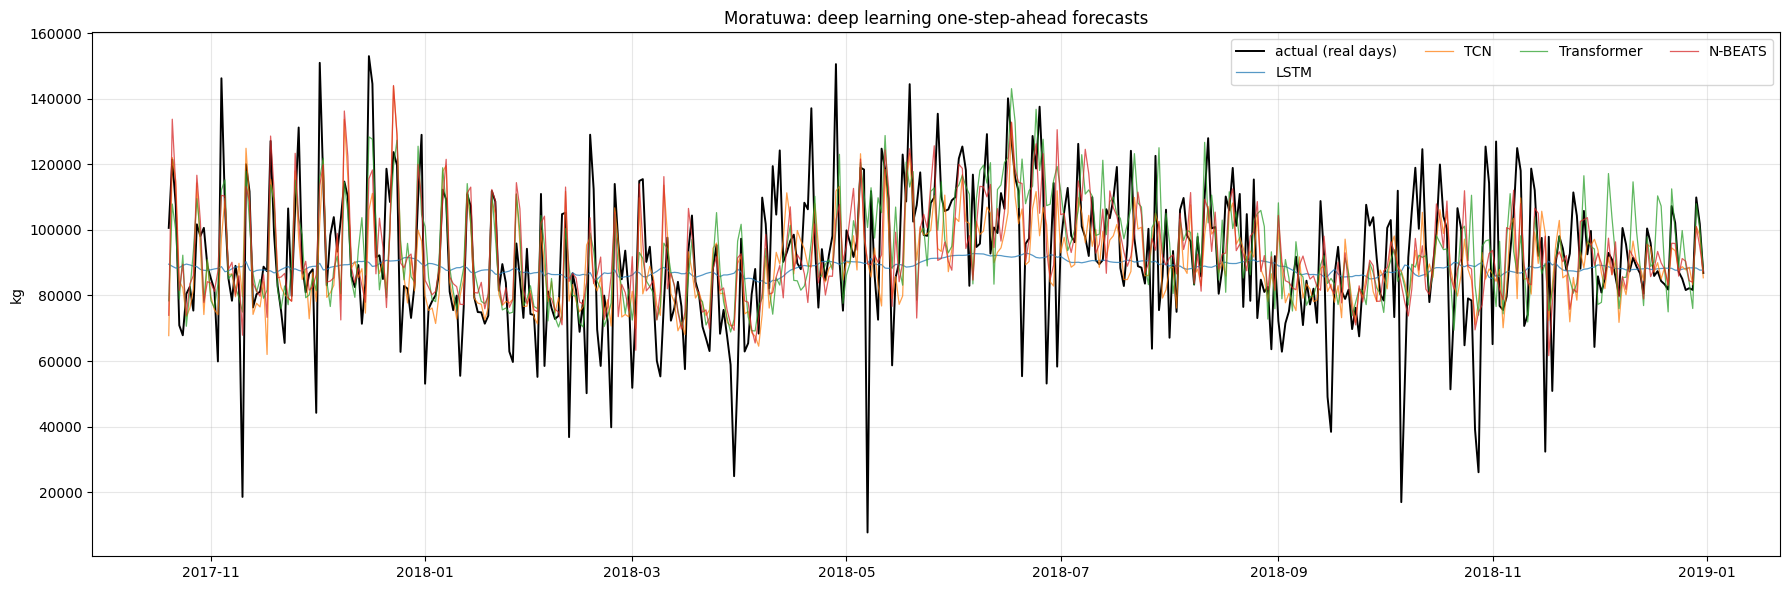

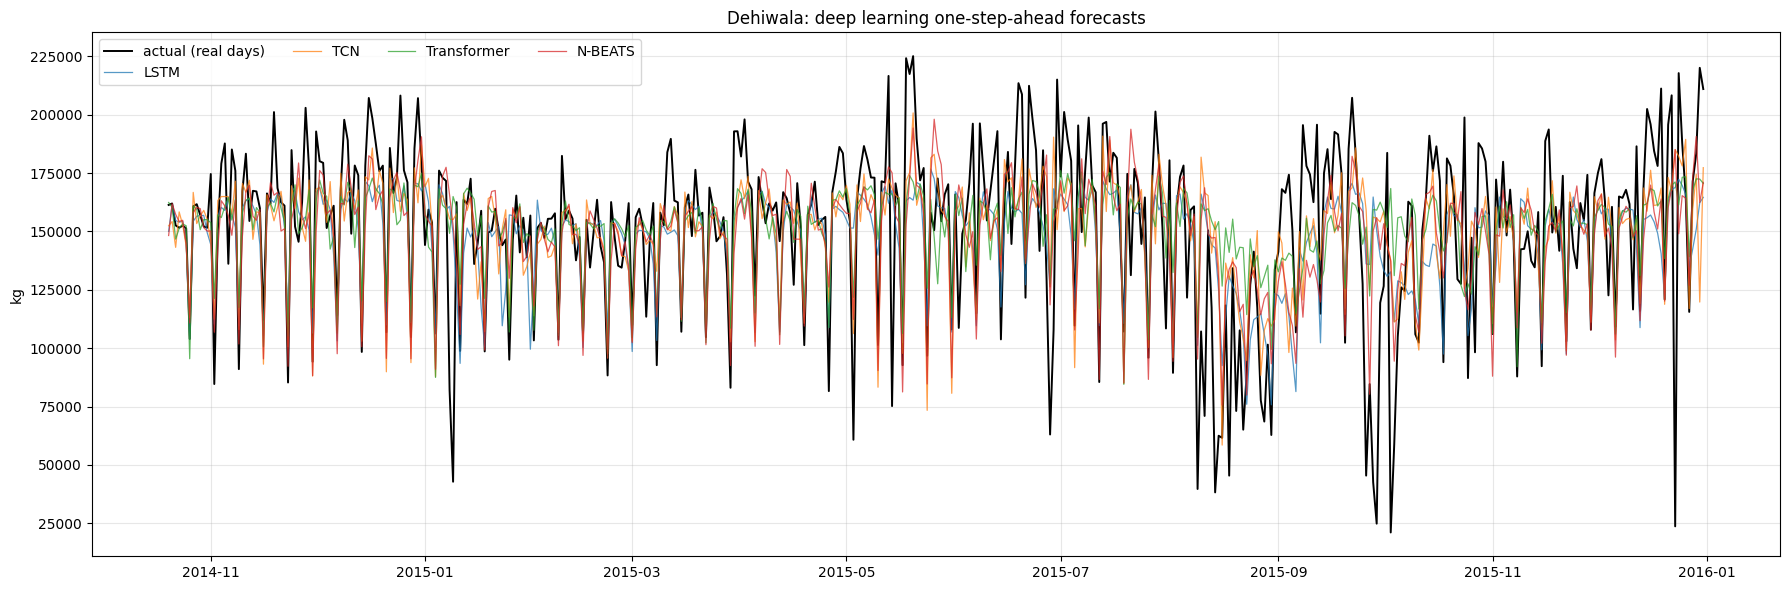

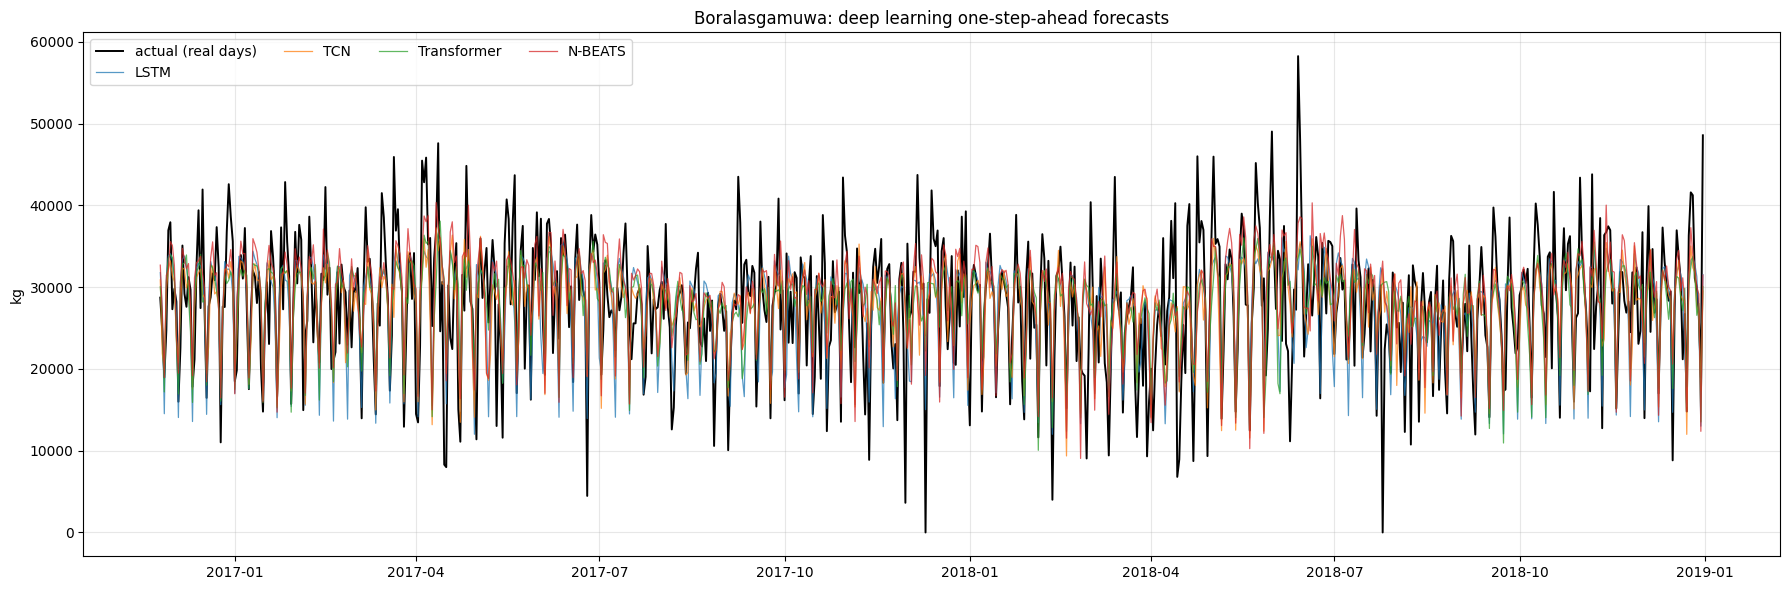

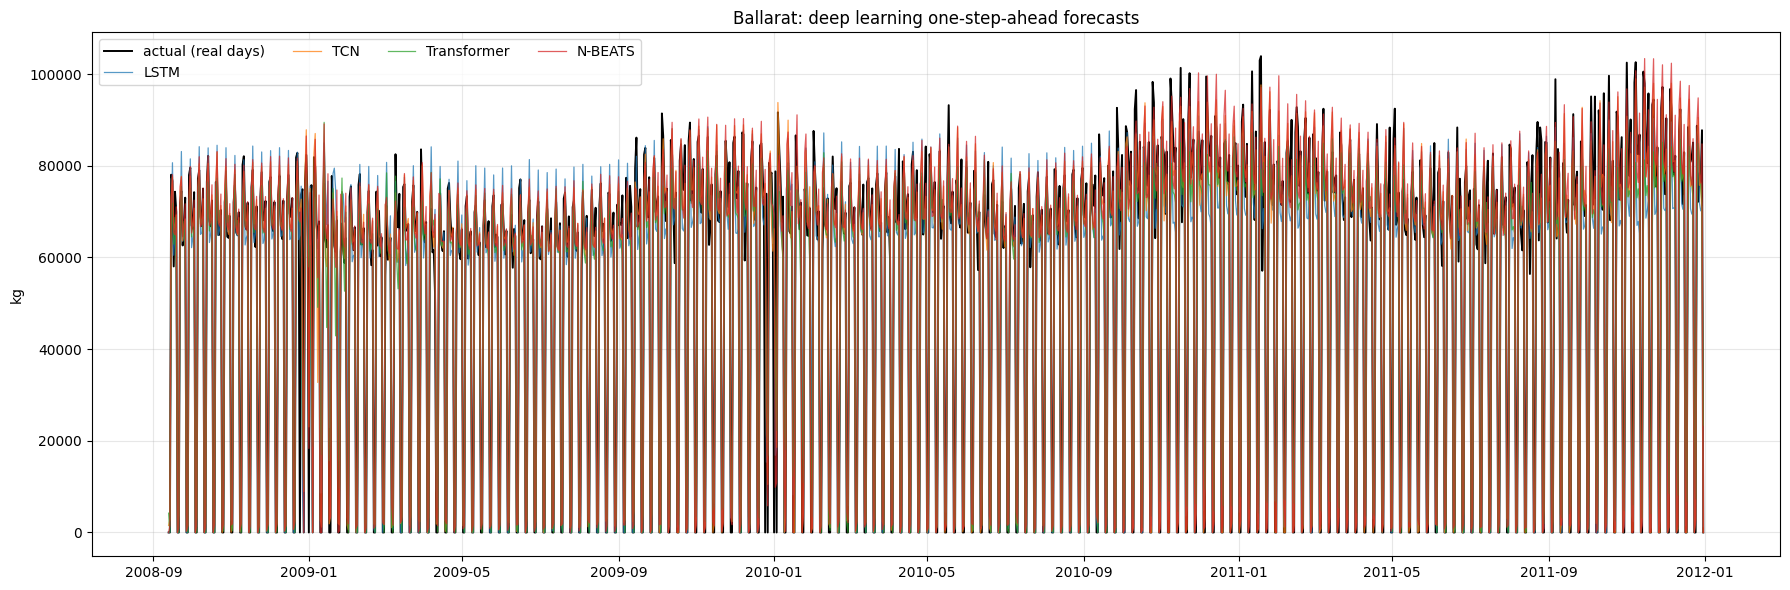

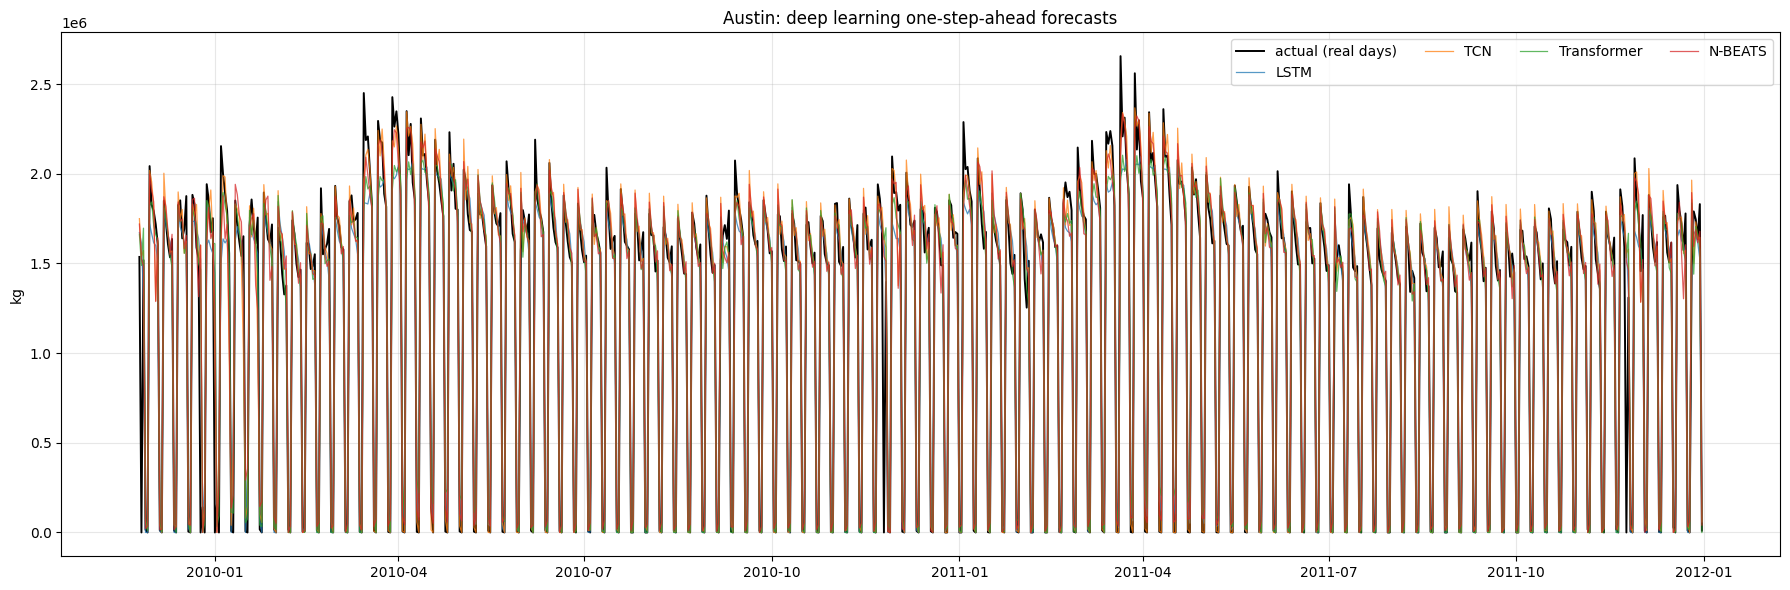

In [12]:
for dataset in data:
    keys = [k for k in all_predictions if k[0] == dataset]
    if not keys:
        continue
    fig, ax = plt.subplots(figsize=(18, 6))
    first = all_predictions[keys[0]]
    ax.plot(first.index, first["actual"].where(first["scored"]), color="black", lw=1.4, label="actual (real days)")
    for _, model_name in keys:
        r = all_predictions[(dataset, model_name)]
        ax.plot(r.index, r["predicted"], lw=0.9, alpha=0.75, label=model_name)
    ax.set_title(f"{dataset}: deep learning one-step-ahead forecasts"); ax.set_ylabel("kg")
    ax.legend(ncol=4); ax.grid(alpha=0.3); fig.tight_layout()
    fig.savefig(os.path.join(OUTPUT_DIR, safe_name(dataset), "plot_all_models.png"), dpi=120)
    plt.show()

## 10. Saved outputs (`results_dl/`)

| File | Content |
|---|---|
| `<dataset>/predictions_<model>.csv` | date, actual, predicted (kg), scored |
| `<dataset>/history_<model>.csv`, `loss_<model>.png` | training and validation loss per epoch of the selected model |
| `<dataset>/selection_<model>.csv` | every candidate setting with its validation RMSE, epochs and parameter count |
| `<dataset>/plot_<model>.png`, `plot_all_models.png` | actual vs predicted on the test period |
| `metrics_all.csv` | MAE, RMSE, MAPE, lookback, selected settings, validation RMSE, training time |
| `model_ranking.csv` | rank per dataset and mean rank |
| `all_approaches_comparison.csv` | DL vs ML single (02) vs ML weekday multi (03) |
| `errors.csv` | failed combinations (only if any) |

**Reproducibility note:** seeds are fixed. GPU and TPU kernels can still give slightly different results from run to run, which is normal for deep learning.